In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb
color_pal = sns.color_palette()
plt.style.use('fivethirtyeight')


In [45]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [46]:
df = pd.read_csv("PJME_hourly.csv")
print(df.head())

df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.set_index('Datetime')
df = df.sort_index()

              Datetime  PJME_MW
0  2002-12-31 01:00:00  26498.0
1  2002-12-31 02:00:00  25147.0
2  2002-12-31 03:00:00  24574.0
3  2002-12-31 04:00:00  24393.0
4  2002-12-31 05:00:00  24860.0


<Axes: title={'center': 'PJME Energy Use in MW'}, xlabel='Datetime'>

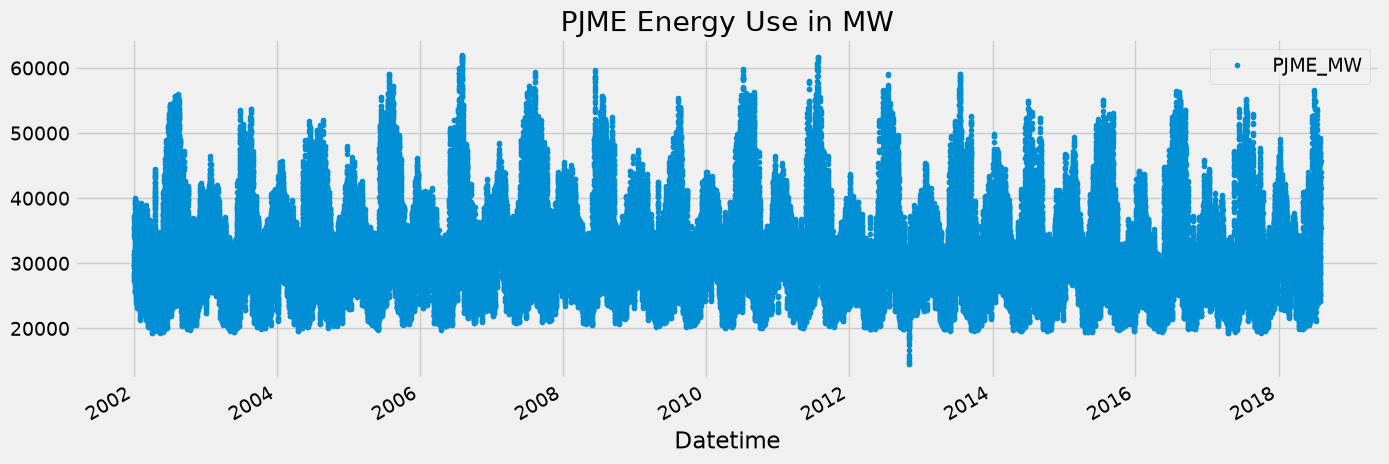

In [47]:
df.plot(style='.', 
        figsize=(15,5), 
        color=color_pal[0],   #
        title='PJME Energy Use in MW')
# PJM = Pennsylvania, New Jersey, Maryland   # E = East


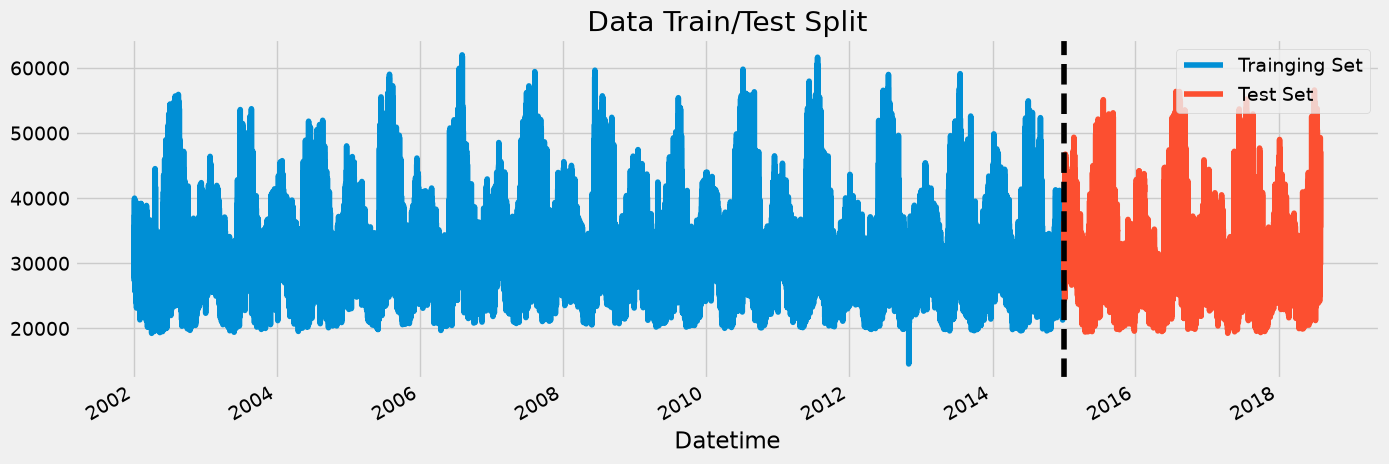

In [48]:
# Train/Test Split
# Time Series Forecasting
# 2015年以前的数据拿来训练模型，把2015年及以后的数据留作测试，然后画图看看这两部分数据
train = df.loc[df.index < '01-01-2015']
test = df.loc[df.index >= '01-01-2015']

fig, ax = plt.subplots(figsize=(15,5))
train.plot(ax=ax, label='Training Set', title='Data Train/Test Split')
test.plot(ax=ax, label='Test Set')
ax.axvline('01-01-2015', color='black', ls='--')
ax.legend(['Trainging Set', 'Test Set'])
plt.show()

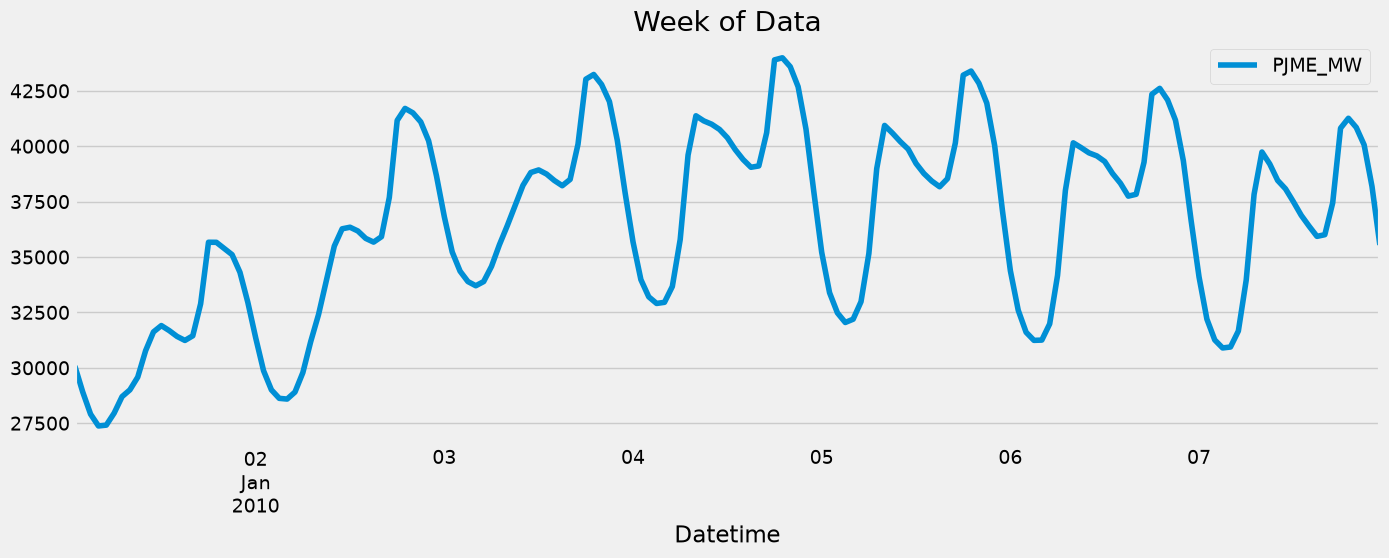

In [49]:
df = df.sort_index()
ax = df.loc[(df.index > '01-01-2010') & (df.index < '01-08-2010')].plot(figsize=(15,5), title='Week of Data')



In [50]:
df.index

DatetimeIndex(['2002-01-01 01:00:00', '2002-01-01 02:00:00',
               '2002-01-01 03:00:00', '2002-01-01 04:00:00',
               '2002-01-01 05:00:00', '2002-01-01 06:00:00',
               '2002-01-01 07:00:00', '2002-01-01 08:00:00',
               '2002-01-01 09:00:00', '2002-01-01 10:00:00',
               ...
               '2018-08-02 15:00:00', '2018-08-02 16:00:00',
               '2018-08-02 17:00:00', '2018-08-02 18:00:00',
               '2018-08-02 19:00:00', '2018-08-02 20:00:00',
               '2018-08-02 21:00:00', '2018-08-02 22:00:00',
               '2018-08-02 23:00:00', '2018-08-03 00:00:00'],
              dtype='datetime64[us]', name='Datetime', length=145366, freq=None)

In [51]:
df.head()

,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [52]:
# Feature Creation
# 把 Datetime 中的日期和时间信息拆分成多个新列，让 XGBoost 能够学习电力消耗与时间之间的关系
def create_features(df):
    """
    Create time series features based on time series index.
    """
    df = df.copy()
    df['hour'] = df.index.hour
    df['dayofweek'] = df.index.dayofweek
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.dayofyear
    df['dayofmonth'] = df.index.day
    df['weekofyear'] = df.index.isocalendar().week
    return df

df = create_features(df)


Text(0.5, 1.0, 'MW by Hour')

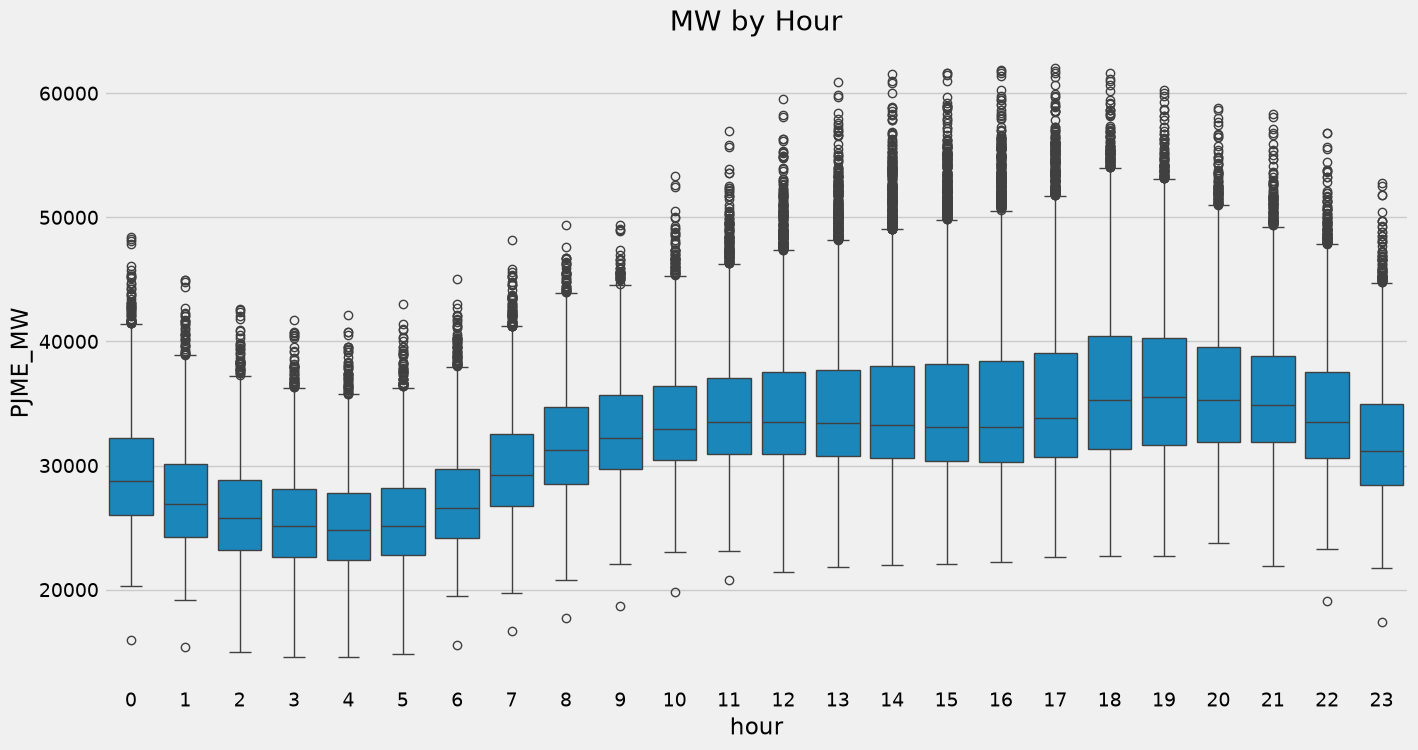

In [53]:
# Visualize our Feature/Target Relation
fig, ax = plt.subplots(figsize=(15,8))
sns.boxplot(data=df, x='hour', y ='PJME_MW')
ax.set_title('MW by Hour')
# Boxplot
# 蓝色方块比较薄，说明不同日子的用电量差距相对小
# 蓝色方块比较厚，说明不同日子的用电量差距相对大

Text(0.5, 1.0, 'MW by Month')

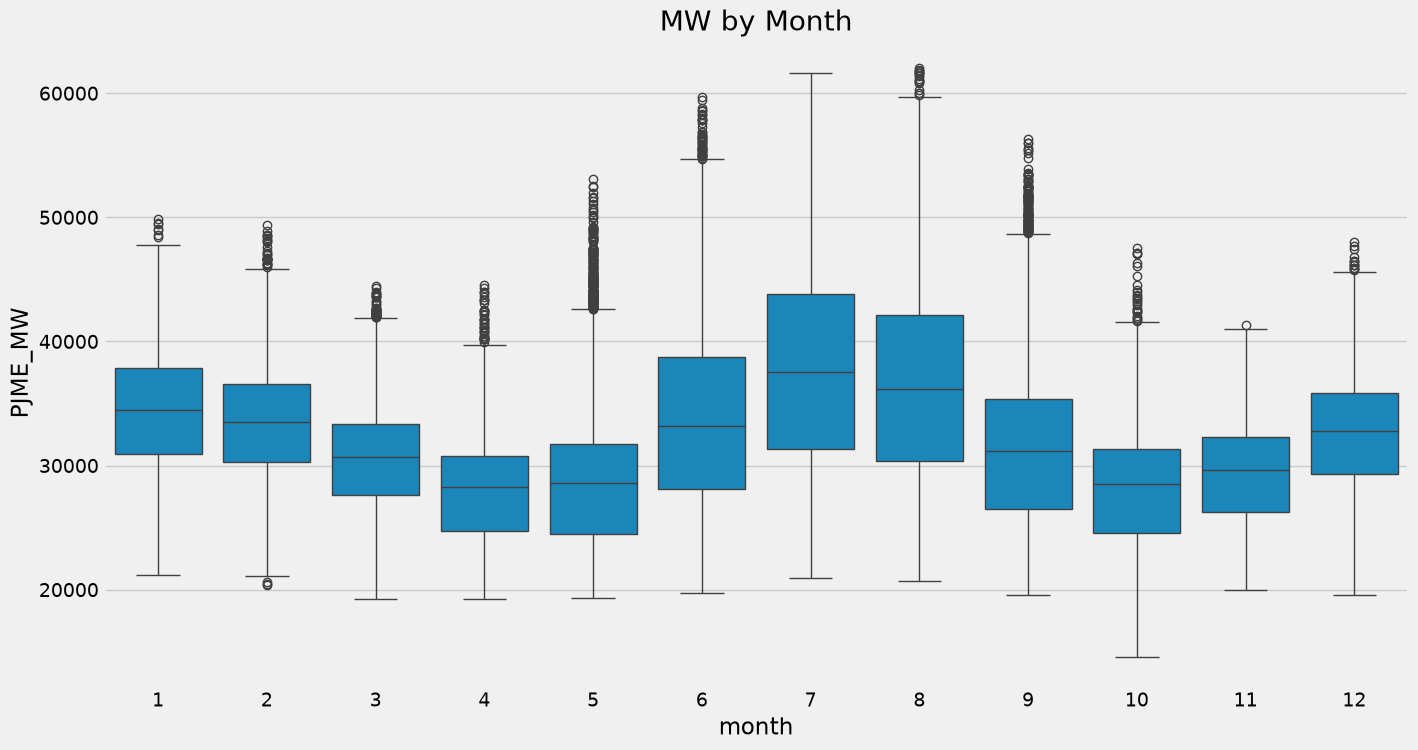

In [54]:
fig, ax = plt.subplots(figsize=(15,8))
sns.boxplot(data=df, x='month', y ='PJME_MW')
ax.set_title('MW by Month')

In [55]:
##################   【Create Model】  #####################

In [56]:
# X（Features）：根据什么信息来预测？

train = create_features(train)
test = create_features(test)

FEATURES = ['hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear','dayofmonth','weekofyear']
TARGET = 'PJME_MW'


In [57]:
X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

In [58]:
reg = xgb.XGBRegressor(n_estimators=1000, early_stopping_rounds = 50,
                       learning_rate = 0.01)
reg.fit(X_train, y_train,
        eval_set = [(X_train, y_train), (X_test, y_test)],
        verbose = True) # 显示详细的运行过程（输出训练日志）

[0]	validation_0-rmse:6407.32200	validation_1-rmse:6479.86327
[1]	validation_0-rmse:6362.92530	validation_1-rmse:6438.63632
[2]	validation_0-rmse:6319.21339	validation_1-rmse:6398.24136
[3]	validation_0-rmse:6275.95586	validation_1-rmse:6358.75952
[4]	validation_0-rmse:6233.26766	validation_1-rmse:6319.81111
[5]	validation_0-rmse:6191.21842	validation_1-rmse:6281.24305
[6]	validation_0-rmse:6149.66894	validation_1-rmse:6243.61796
[7]	validation_0-rmse:6108.71862	validation_1-rmse:6206.01842
[8]	validation_0-rmse:6068.22672	validation_1-rmse:6169.33350
[9]	validation_0-rmse:6028.31885	validation_1-rmse:6132.88106
[10]	validation_0-rmse:5988.93945	validation_1-rmse:6097.35010
[11]	validation_0-rmse:5950.04040	validation_1-rmse:6061.82285
[12]	validation_0-rmse:5911.29230	validation_1-rmse:6026.76201
[13]	validation_0-rmse:5873.10155	validation_1-rmse:5992.43816
[14]	validation_0-rmse:5835.70638	validation_1-rmse:5959.13047
[15]	validation_0-rmse:5798.38814	validation_1-rmse:5925.95026
[1

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [59]:
# Feature Importance 
# XGBoost 在预测电力消耗量（MW）时，最依赖哪些信息？

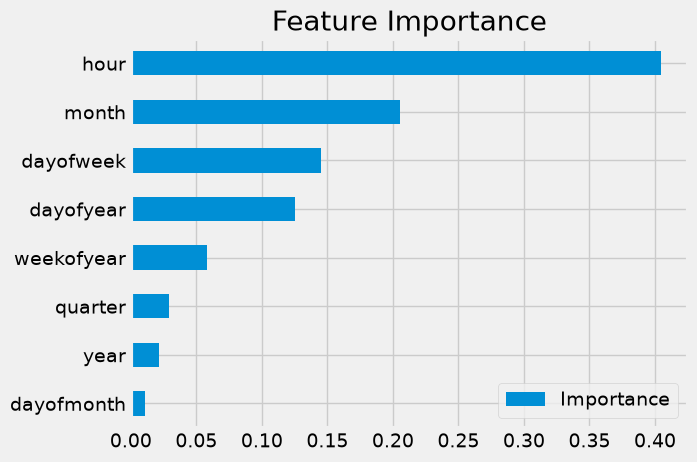

In [60]:
fi = pd.DataFrame(data=reg.feature_importances_, 
             index=reg.feature_names_in_,
             columns=['Importance'])
fi.sort_values('Importance').plot(kind='barh',title='Feature Importance')
plt.show()

In [61]:
### Prediction Visualization ### XGBoost 预测出来的电力消耗量和真实数据相差多少？

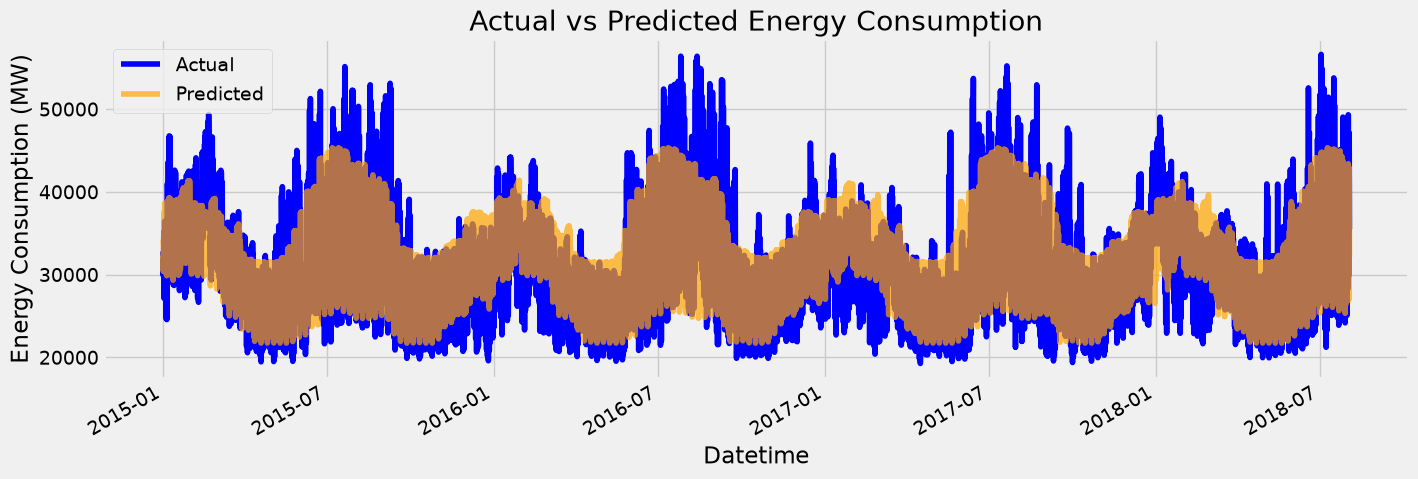

In [62]:
# Make predictions
test = test.copy()
test['prediction'] = reg.predict(X_test)

# Compare actual and predicted values
fig, ax = plt.subplots(figsize=(15, 5))

test['PJME_MW'].plot(
    ax=ax,
    label='Actual',
    color='blue'
)

test['prediction'].plot(
    ax=ax,
    label='Predicted',
    color='orange',
    alpha=0.7           # Transparency
)

ax.set_title('Actual vs Predicted Energy Consumption')
ax.set_ylabel('Energy Consumption (MW)')
ax.legend()
plt.show()

In [63]:
y_pred = reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f'MAE: {mae:.2f} MW')
print(f'RMSE: {rmse:.2f} MW')
print(f'MAPE: {mape:.2f}%')

MAE: 2895.09 MW
RMSE: 3738.67 MW
MAPE: 9.20%
